# A bead in the computed trap: spectrum, stiffness and the Boltzmann law

**Question:** What does a trapped bead do in the potential that DinHot computed, and does the power spectrum of its motion give back the stiffness of the trap?

- Level: 1, fundamentals.
- Prerequisites: `03-gerchberg-saxton/02-weights-for-uniformity` for the hologram, and `01-fourier-optics/02-reading-a-trap-array` for the trap intensities.
- Reading time: about 25 minutes. The notebook runs in about a minute.

## Objectives

A hologram is judged by the numbers of the previous topics, equal traps and a high efficiency, but its purpose is to hold something. This notebook closes the loop: it takes the intensity that a hologram produces, turns it into the potential a bead feels, lets the bead diffuse in it, and asks whether an experimenter who watched the bead could recover the trap stiffness from its motion. That is how optical tweezers are calibrated, and it is the check that the physics of the product is consistent with itself. By the end you can:

- turn a focal intensity map into a trap depth and a stiffness, with the units kept;
- say what an overdamped bead does, and what step of the integrator is stable;
- compute the power spectrum of the position, fit a Lorentzian, and read the corner frequency;
- test the simulated position histogram against the Boltzmann law;
- say what the check proves, and what it leaves open.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.dynamics import BeadParams, bead_trajectory, boltzmann_check, fit_lorentzian, psd
from pipeline.model.holo.core.forward import point_trap_fields
from pipeline.model.holo.core.geometry import focal_bin_m
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import Trap, TrapSet
from pipeline.model.holo.core.trapphys import C_M_PER_S, EPS0_F_PER_M, KB_J_PER_K, rayleigh_polarizability_Fm2
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook reads case C01 of `data/examples/cases.json`: a 3 x 3 array with a polystyrene-like bead in its central trap.

- Owner: this repository; the case is synthetic, with the bead and the fluid stated in the record and the array on the case's atom-type optical setup.
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C01 (the `dynamics` block carries the bead).

In [2]:
# case C01: a 3 x 3 array, and the record of the bead that sits in its central trap
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C01"]
setup = build.setup_of(rec)
target = build.target_of(rec)
bead = rec["dynamics"]
print(rec["case_id"], "|", len(target.traps), "traps | trap id of the bead:", bead["trap_id"])
keys = ("bead_radius_um", "n_particle", "power_mw", "viscosity_pa_s", "temperature_k", "n_steps", "dt_s")
print({k: bead[k] for k in keys})

C01_square_grid | 9 traps | trap id of the bead: 4
{'bead_radius_um': 0.5, 'n_particle': 1.59, 'power_mw': 10.0, 'viscosity_pa_s': 0.00089, 'temperature_k': 295.0, 'n_steps': 131072, 'dt_s': 5e-05}


## Method

### Step 1: a hologram, and the intensity it leaves around one trap

A small dielectric sphere in a focused beam feels the gradient force $F = \tfrac{1}{2}\,\mathrm{Re}(\alpha)\,\nabla I / (c\,\epsilon_0)$, where $\alpha$ is its polarizability and $I$ the intensity. In the Rayleigh regime $\alpha = 4\pi r^3 \epsilon_0 (\epsilon_r - 1)/(\epsilon_r + 2)$ with $\epsilon_r = (n_\text{particle}/n_\text{medium})^2$ (Grimm, Weidemuller and Ovchinnikov, 2000, for the dipole force; the pipeline's physics card for the sphere). The force is the gradient of a potential $U(\mathbf r) = -U_0\, I(\mathbf r)/I_\text{max}$ with $U_0 = \alpha I_\text{max} / (2 c \epsilon_0)$, so the bead sits in the same intensity map that the hologram computes. The first cell computes the hologram of the 3 x 3 array with weighted Gerchberg-Saxton (M06).

In [3]:
# the hologram of the array: weighted GS on the ideal model, 30 iterations
res = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1))
h = res.history[-1]
print(f"efficiency {h['efficiency']:.4f} | uniformity {h['uniformity']:.4f} | "
      f"rel. std {h['rel_std']:.2f} %")

efficiency 0.8166 | uniformity 1.0000 | rel. std 0.00 %


The array is perfectly equal (uniformity 1.0000) with 0.8166 of the light in the nine traps. The potential needs more than the nine numbers $I_m$: it needs the shape of one spot, so the next cell evaluates the intensity of the hologram on a fine grid, 51 x 51 points a tenth of an FFT bin apart, around the central trap. The point-trap form evaluates the field at any position, not only at the bins of the FFT.

In [4]:
# the intensity around the central trap: 51 x 51 points, 0.1 FFT bin apart, from the point-trap form
bin_m = focal_bin_m(setup)
site = next(t for t in rec["target"]["traps"] if t["id"] == bead["trap_id"])
side = 51
offset = (np.arange(side) - side // 2) * 0.1 * bin_m
xs, ys = site["x_um"] * 1e-6 + offset, site["y_um"] * 1e-6 + offset
grid = TrapSet(Trap(iy * side + ix, float(xs[ix]), float(ys[iy]), 0.0) for iy in range(side) for ix in range(side))
inten = (np.abs(point_trap_fields(res.phi, setup, grid)) ** 2).reshape(side, side)
iy_max, ix_max = np.unravel_index(int(np.argmax(inten)), inten.shape)
print(f"peak of the map: {inten.max():.4f} of the input power")
print(f"position of the peak from the trap centre (um): "
      f"{(xs[ix_max] - site['x_um'] * 1e-6) * 1e6:.3f}, {(ys[iy_max] - site['y_um'] * 1e-6) * 1e6:.3f}")

peak of the map: 0.0907 of the input power
position of the peak from the trap centre (um): 0.000, 0.000


The peak of the map is 0.0907 of the input power, at the centre of the trap, as it should be. To turn it into newtons the cell scales by the laser power on the SLM, 10 mW, divided by the area of one bin on the focal plane (one bin carries $1/\text{pad}^2$ of the power of a peak), takes the depth $U_0$ from the polarizability, and the curvature of $I/I_\text{max}$ at the peak from a second difference with a stencil of two grid steps. The stiffness along $x$ is $\kappa = U_0 \times$ curvature. The drag is Stokes', $\gamma = 6\pi\eta r$, and the overdamped bead then has a relaxation time $\tau = \gamma/\kappa$ and a corner frequency $f_c = \kappa / (2\pi\gamma)$ (Tolic-Norrelykke et al., 2006).

In [5]:
# from the map to the physics: trap depth, stiffness along x, drag, and the expected corner frequency
power = bead["power_mw"] * 1e-3
peak_intensity = inten.max() * power / (setup.pad**2 * bin_m**2)
alpha = rayleigh_polarizability_Fm2(bead["bead_radius_um"] * 1e-6, bead["n_particle"], setup.n_imm)
depth = alpha * peak_intensity / (2.0 * C_M_PER_S * EPS0_F_PER_M)
step = 0.1 * bin_m
peak_row = inten[iy_max]
curvature = -(peak_row[ix_max + 2] - 2 * peak_row[ix_max] + peak_row[ix_max - 2]) / (2 * step) ** 2 / inten.max()
kappa = depth * curvature
gamma = 6.0 * np.pi * bead["viscosity_pa_s"] * bead["bead_radius_um"] * 1e-6
fc_expected = kappa / (2.0 * np.pi * gamma)
kt = KB_J_PER_K * bead["temperature_k"]
print(f"depth {depth / kt:.1f} kBT | stiffness {kappa * 1e6:.2f} pN/um | "
      f"drag {gamma:.3e} N s/m")
print(f"expected corner frequency {fc_expected:.2f} Hz | "
      f"relaxation time {gamma / kappa * 1e3:.3f} ms")

depth 198.5 kBT | stiffness 4.08 pN/um | drag 8.388e-09 N s/m
expected corner frequency 77.32 Hz | relaxation time 2.058 ms


The bead is 198.5 times deeper in the potential than the thermal energy, with a stiffness of 4.08 pN/um, a relaxation time of 2.058 ms and an expected corner frequency of 77.32 Hz. The magnitude of the depth inherits a caveat of the pipeline's physics card: the polarizability keeps the vacuum prefactor and the extra medium factors of a bead in a fluid are not in the sections the pipeline read, so the absolute stiffness is a model value and not a measurement. The check below does not depend on it, because the spectrum is tested against the stiffness the simulation itself used.

### Step 2: the Langevin run

An overdamped bead obeys $x_{n+1} = x_n + (\Delta t/\gamma)\,F(x_n) + \sqrt{2 D \Delta t}\,\zeta_n$, with $D = k_B T/\gamma$ and $\zeta_n$ a standard normal number from the seeded generator. The step must resolve the relaxation, and the pipeline's rule is $\Delta t \le \tau/20$. The record's step of 50 us is already below $\tau/20$ = 103 us, so the cell integrates with the record's step; it keeps the general form, which refines the step and thins the trace when a stiffer trap needs it. It runs 131072 steps and compares the spread of the position with the equipartition value $\sqrt{k_B T/\kappa}$.

In [6]:
# the Langevin run: the record's step, refined until it is at most tau / 20, then thinned back to the
# record's step
tau = gamma / kappa
sub = max(1, int(np.ceil(bead["dt_s"] / (tau / 20))))
start = (xs[ix_max], ys[iy_max])
params = BeadParams(depth, gamma, bead["temperature_k"], start)
dt_fine = bead["dt_s"] / sub
track = bead_trajectory(inten, (xs, ys), params, bead["n_steps"] * sub, dt_fine, Rng(rec["seed"] + 7919))[::sub]
x = track[:, 0] - start[0]
print(f"integrator steps per record step: {sub} | samples: {len(x)}")
print(f"rms position {x.std() * 1e9:.1f} nm | equipartition sqrt(kBT / kappa) "
      f"{np.sqrt(kt / kappa) * 1e9:.1f} nm")

integrator steps per record step: 1 | samples: 131073
rms position 32.7 nm | equipartition sqrt(kBT / kappa) 31.6 nm


The left panel overlays the first 3000 positions of the bead on the intensity map, and the right panel shows 2000 samples of the x position against time.

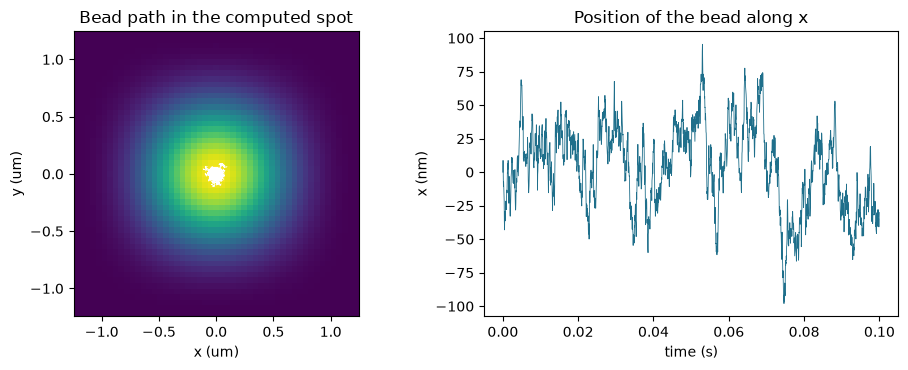

In [7]:
# left: the intensity map with the first 3000 positions of the bead; right: the x position against time
fig, (a, b) = plt.subplots(1, 2, figsize=(9.6, 3.8))
extent = [(xs[0] - start[0]) * 1e6, (xs[-1] - start[0]) * 1e6, (ys[0] - start[1]) * 1e6, (ys[-1] - start[1]) * 1e6]
a.imshow(inten, origin="lower", extent=extent, cmap="viridis")
a.plot((track[:3000, 0] - start[0]) * 1e6, (track[:3000, 1] - start[1]) * 1e6, "w-", linewidth=0.4)
a.set_xlabel("x (um)")
a.set_ylabel("y (um)")
a.set_title("Bead path in the computed spot")
t_axis = np.arange(2000) * bead["dt_s"]
b.plot(t_axis, x[:2000] * 1e9, color="#1f6f8b", linewidth=0.6)
b.set_xlabel("time (s)")
b.set_ylabel("x (nm)")
b.set_title("Position of the bead along x")
plt.tight_layout()
plt.show()

The rms position is 32.7 nm against the equipartition value of 31.6 nm, a difference of 3 percent that is the statistical error of a finite run: the position correlates over the relaxation time of 2 ms, so 131072 samples of 50 us span only about 3000 relaxation times. In the left panel the bead stays within a tenth of a micrometre of the centre of a spot about a micrometre wide, so it is well inside the region where the potential is nearly harmonic; the white trace covers a tiny fraction of the bright core. In the right panel the position wanders over about 100 nm with correlations that last several milliseconds. The figure shows one bead and one seed; it does not show that the potential is harmonic over the whole path, which the Boltzmann check below tests.

### Step 3: the spectrum and the stiffness

For a bead in a harmonic trap the one-sided power spectrum of the position is a Lorentzian, $P(f) = D / [\pi^2 (f^2 + f_c^2)]$, flat below the corner frequency and falling as $f^{-2}$ above it, with $D = k_B T / \gamma$ the diffusion constant (Tolic-Norrelykke et al., 2006). The cell computes the periodogram of the trace in 64 segments of 2048 samples, averaged, and fits $1/P = a + b f^2$ by weighted least squares on the band up to five times the expected corner frequency, where the model holds; it reads $f_c = \sqrt{a/b}$ and $D = \pi^2/b$.

In [8]:
# the power spectrum of x in 64 segments, and the Lorentzian fitted on the band up to five corner frequencies
freq, power_density = psd(x, bead["dt_s"], 64)
band = freq <= 5 * fc_expected
fc_fit, d_fit = fit_lorentzian(freq[band], power_density[band])
print(f"fitted corner frequency {fc_fit:.2f} Hz | expected {fc_expected:.2f} Hz | "
      f"ratio {fc_fit / fc_expected:.3f}")
print(f"fitted diffusion constant over kBT / gamma: {d_fit / (kt / gamma):.3f}")

fitted corner frequency 71.54 Hz | expected 77.32 Hz | ratio 0.925
fitted diffusion constant over kBT / gamma: 0.975


The spectrum is plotted on log axes with the fitted curve and the expected corner frequency.

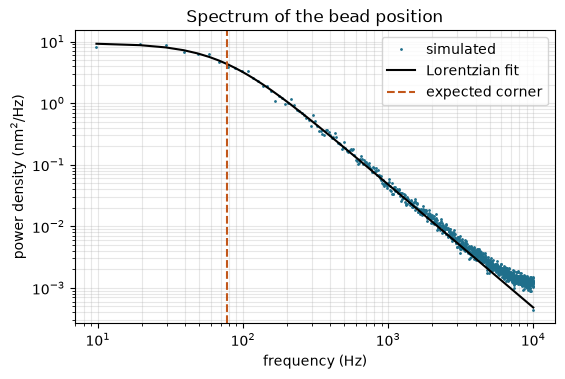

In [9]:
# the spectrum on log axes with the fitted Lorentzian and the expected corner frequency
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.loglog(freq, power_density * 1e18, ".", markersize=2, color="#1f6f8b", label="simulated")
ax.loglog(freq, d_fit / (np.pi**2 * (freq**2 + fc_fit**2)) * 1e18, "k-", label="Lorentzian fit")
ax.axvline(fc_expected, color="#c2571a", linestyle="--", label="expected corner")
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("power density (nm$^2$/Hz)")
ax.set_title("Spectrum of the bead position")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

The simulated spectrum has the Lorentzian shape: a plateau at low frequency, a bend, and a slope of $-2$ over two decades. The fitted corner frequency is 71.54 Hz against the expected 77.32 Hz, a ratio of 0.925, and the fitted diffusion constant is 0.975 of $k_B T/\gamma$. A stiffness read from the spectrum would therefore be low by about 7 percent, which is inside the band of 0.8 to 1.2 that the case card sets for this ratio and in line with the bias that the linearised fit is known to have at a low number of segments. At high frequency the points leave the line and flatten near $10^{-3}$ nm$^2$/Hz, near the Nyquist frequency of 10 kHz: that is the aliasing of the discrete-time integrator, and it is the reason the fit stops at five corner frequencies. The figure shows one seed, so it cannot say how much of the 7.5 percent is bias and how much is noise; the pipeline's engine test repeats the run with three seeds.

### Step 4: the Boltzmann law

A second, independent check does not use the dynamics at all. In equilibrium the probability of finding the bead at $x$ is proportional to $\exp[-U(x)/k_B T]$. The cell builds the potential along the row of the map through the peak, integrates the Boltzmann density over each of 40 position bins, and measures the total variation distance between that and the histogram of the simulated positions (0 for identical, 1 for disjoint).

In [10]:
# the histogram of x against the Boltzmann law of the potential -depth I / I_max along the row through the peak
row = inten[iy_max, :] / inten.max()
check = boltzmann_check(x + start[0], lambda pos: -depth * np.interp(pos, xs, row), bead["temperature_k"])
print(f"total variation between the histogram and the Boltzmann law: "
      f"{check['total_variation']:.4f}")

total variation between the histogram and the Boltzmann law: 0.0463


The bars are the simulated histogram and the black line is the Boltzmann prediction.

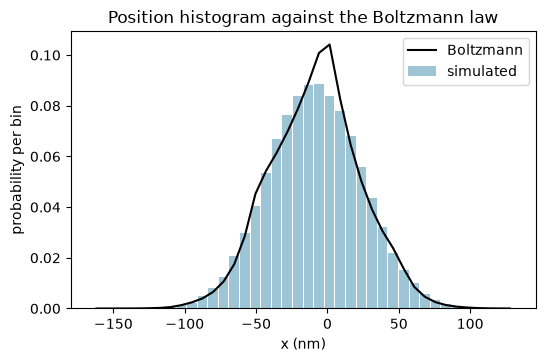

In [11]:
# empirical and expected probability of each position bin
centres = (check["bin_centres_m"] - start[0]) * 1e9
fig, ax = plt.subplots(figsize=(6.0, 3.6))
ax.bar(centres, check["empirical"], width=np.diff(centres).mean() * 0.9, color="#9ec5d6", label="simulated")
ax.plot(centres, check["expected"], "k-", label="Boltzmann")
ax.set_xlabel("x (nm)")
ax.set_ylabel("probability per bin")
ax.set_title("Position histogram against the Boltzmann law")
ax.legend()
plt.show()

The histogram follows the prediction closely: the total variation distance is 0.0463, so the two distributions differ in 4.6 percent of their probability mass, and the bars stay on both sides of the line without a systematic departure at the tails, where an anharmonic potential would show itself. The residual is consistent with the sampling noise of a run that spans about 3000 relaxation times. This check and the spectrum are complementary: the spectrum tests the time scale, which depends on the stiffness and the drag, and the histogram tests the potential, which depends on the stiffness and the temperature. Together they say that the simulated bead is in equilibrium in the potential it was given. They do not say that the potential is the right one for a real bead in a real trap; that depends on the physics of the force and the model of the map.

## Results

**Answer:** A bead in the computed trap behaves as the physics of the potential says, and its power spectrum gives back the stiffness to within about 8 percent. The hologram of the 3 x 3 array puts 0.0907 of the input power into the peak of the central trap, which at 10 mW makes a potential 198.5 kBT deep with a stiffness of 4.08 pN/um, a corner frequency of 77.32 Hz and a relaxation time of 2.058 ms. The simulated bead has an rms position of 32.7 nm against the equipartition value of 31.6 nm, a spectrum with the Lorentzian shape whose fitted corner frequency is 71.54 Hz (a ratio of 0.925 to the expected one), and a position histogram within a total variation distance of 0.0463 of the Boltzmann law.

What the notebook does not show is how the ratio of 0.925 varies with the seed, or any bead other than a sphere in the Rayleigh regime; the absolute value of the stiffness carries the vacuum-prefactor caveat of the pipeline.

## Summary

- The intensity map of a hologram is a potential, $U = -U_0 I/I_\text{max}$, whose depth, stiffness and corner frequency follow from the polarizability, the laser power and the curvature of the spot.
- An overdamped bead is integrated with a step of at most $\tau/20$; its rms position matches equipartition to 3 percent.
- The Lorentzian fit to the position spectrum returns the corner frequency to within 7.5 percent of the one used, and the diffusion constant to 2.5 percent.
- The position histogram matches the Boltzmann law of the potential to a total variation distance of 0.0463.
- The check is internal: it shows the simulation agrees with its own potential, not that the potential matches an instrument.

## References

- Tolic-Norrelykke et al. (2006). Calibration of optical tweezers with positional detection in the back focal plane. Review of Scientific Instruments 77, 103101. https://arxiv.org/abs/physics/0603037
- Grimm, Weidemuller and Ovchinnikov (2000). Optical dipole traps for neutral atoms. https://arxiv.org/abs/physics/9902072